# Carbon footprint of operating-room products: calculation methods

**Prototype for demonstration** · Hamdan & Sewar · SCE final project · Supervisor: Dr. Hadas Chassidim

This notebook implements the calculation methods compared in the Literature Review (Chapter 3, Tables 7–8, and Table 11) and runs them on real products with emission factors taken from published sources.

All the methods use the same principle:

$$CF = Q \times EF$$

where $Q$ is the activity data (a quantity, a mass, or a price) and $EF$ is an emission factor. The methods differ in what $Q$ is and where $EF$ comes from:

| Method | Activity data $Q$ | Emission factor $EF$ | Tier (Table 11) |
|---|---|---|---|
| **A. Product-level LCA** | number of units | kg CO₂e per unit, from a published LCA of the same or an equivalent product | 2 |
| **B. Material-based** | mass of each material | kg CO₂e per kg of material, plus a factor for the waste route | 3 (lower bound) |
| **C. Spend-based** | price, converted to the currency and year of the factor | kg CO₂e per US dollar for the industry | 4 |
| **Anaesthetic gases** | mass of agent released | GWP100 of the agent | direct emission |


In [1]:
import sys; sys.path.insert(0, '..')
import pandas as pd
import matplotlib.pyplot as plt
import orcarbon as oc

db = oc.load()
pd.DataFrame(db.factors.values())[['factor_id', 'key', 'value', 'unit', 'geography', 'year', 'source_id']]

,factor_id,key,value,unit,geography,year,source_id
0,MAT_PP,polypropylene,3.104727,kg CO2e per kg,UK,2022,DEFRA_2022_PP
1,MAT_RUBBER,synthetic_rubber,3.420000,kg CO2e per kg,Australia,2019,ICM_2019_RUBBER
2,WASTE_HTI,high_temperature_incineration,1.074000,kg CO2e per kg,UK hospital,2021,RIZAN_WASTE
3,WASTE_AUTOCLAVE_EFW,autoclave_then_energy_from_waste,0.569000,kg CO2e per kg,UK hospital,2021,RIZAN_WASTE
4,WASTE_EFW,energy_from_waste,0.172000,kg CO2e per kg,UK hospital,2021,RIZAN_WASTE
5,SPEND_339113,NAICS_339113,0.140000,kg CO2e per USD (2022 purchaser price),USA,2022,EPA_USEEIO


## Method A: product-level LCA (Tier 2)

$$CF = \text{quantity} \times EF_{\text{product}}$$

Rizan et al. carried out a cradle-to-grave LCA of personal protective equipment (ISO 14044, ecoinvent 3.6): raw materials, manufacture, transport, packaging and high-temperature incineration. Their per-item results are used directly as the emission factor of each product.

In [2]:
r = oc.product_lca(db, 'GLOVE_NITRILE')
print(*r.steps, sep='\n')

Emission factor of the product: 26 g CO2e per one glove (cradle-to-grave (materials manufacture transport packaging high-temperature incineration)).
CF = quantity x EF = 1 x 0.026 kg = 0.0260 kg CO2e.


## Method B: material-based (Tier 3)

$$CF = \sum_i m_i \times EF_{\text{material}(i)} \; + \; m_{\text{total}} \times EF_{\text{waste route}}$$

The masses of each component come from Rizan et al. (Table 2). Material factors: polypropylene from the UK government conversion factors (2022), synthetic rubber from the ICM database (2019). Disposal: high-temperature incineration, 1,074 kg CO₂e per tonne (Rizan et al., 2021, hospital waste streams).

Manufacturing energy, transport and packaging are **not** included, so the result is a **lower bound**. The method also reports the share of the product's mass that had an emission factor (a completeness check, ISO 14044).

In [3]:
for p in ['GLOVE_NITRILE', 'MASK_IIR']:
    r = oc.material_based(db, p)
    print(db.products[p]['name'], f'(coverage {r.coverage:.0%})')
    print(*['   ' + s for s in r.steps], sep='\n')
    print(*['   ! ' + w for w in r.warnings], sep='\n'); print()

Nitrile examination glove (coverage 100%)
   glove: 3.23 g synthetic rubber x 3.420 kg CO2e/kg = 11.05 g CO2e
   disposal (high temperature incineration): 3.23 g x 1.074 kg CO2e/kg = 3.47 g CO2e
   CF = 1 x (11.05 + 3.47) g = 14.52 g CO2e
   ! Manufacturing energy, transport and packaging are not included, so this is a lower bound.

Surgical face mask (Type IIR) (coverage 94%)
   non-woven layers: 1.63 g polypropylene x 3.105 kg CO2e/kg = 5.06 g CO2e
   melt-blown filter layer: 0.82 g polypropylene x 3.105 kg CO2e/kg = 2.55 g CO2e
   ear loops: 0.45 g synthetic rubber x 3.420 kg CO2e/kg = 1.54 g CO2e
   disposal (high temperature incineration): 3.1 g x 1.074 kg CO2e/kg = 3.33 g CO2e
   CF = 1 x (9.15 + 3.33) g = 12.47 g CO2e
   ! No emission factor for 'aluminium' (nose wire, 0.2 g); this part is left out of production emissions.
   ! Manufacturing energy, transport and packaging are not included, so this is a lower bound.



## Method C: spend-based (Tier 4)

$$CF = \text{price}_{\text{USD 2022}} \times EF_{\text{industry}}$$

The EPA factor for NAICS 339113 (surgical appliances and supplies, which include examination gloves and surgical drapes) is 0.14 kg CO₂e per US dollar of 2022. The price must first be converted to the same currency and year:

1. **Currency:** the public price list (Alberta Health Services, 2023) is in Canadian dollars, so it is divided by the 2023 exchange rate (1.3497 CAD per USD, Bank of Canada).
2. **Year:** 2023 dollars are converted to 2022 dollars with the consumer price index (CPI-U 2022 / CPI-U 2023).

No Israeli purchase prices are available yet; a Soroka price can replace the published one (`price=..., currency=..., price_year=...`).

In [4]:
r = oc.spend_based(db, 'GLOVE_NITRILE')
print(*r.steps, sep='\n')

price: 0.231 CAD per unit (2023)
currency: 0.231 CAD / 1.3497 CAD per USD = 0.1711 USD (2023)
price year: x CPI 2022 / CPI 2023 = x 292.655/304.702 = 0.1644 USD (2022)
CF = 1 x 0.1644 USD x 0.14 kg CO2e/USD (NAICS 339113) = 23.01 g CO2e


## Comparing the three methods on the same products

In [5]:
rows = []
for p in db.products:
    row = {'product': db.products[p]['name']}
    for r in oc.compare(db, p):
        row[r.name] = round(r.g_co2e, 1) if r.available else None
    row['hybrid choice'] = oc.hybrid(db, p).name
    rows.append(row)
table = pd.DataFrame(rows).set_index('product')
table.columns = [c if c == 'hybrid choice' else c + ' (g CO2e)' for c in table.columns]
table

,A. Product-level LCA (g CO2e),B. Material-based (g CO2e),C. Spend-based (g CO2e),hybrid choice
product,,,,
Nitrile examination glove,26.0,14.5,23.0,A. Product-level LCA
Surgical face mask (Type IIR),20.0,12.5,93.2,A. Product-level LCA
Single-use surgical gown (reinforced),905.0,597.7,366.6,A. Product-level LCA
Single-use surgical drapes for one gynecological operation,NaN,2467.8,NaN,B. Material-based
"Nitrile examination glove, Top Glove 3.5 g",27.7,15.7,23.0,A. Product-level LCA


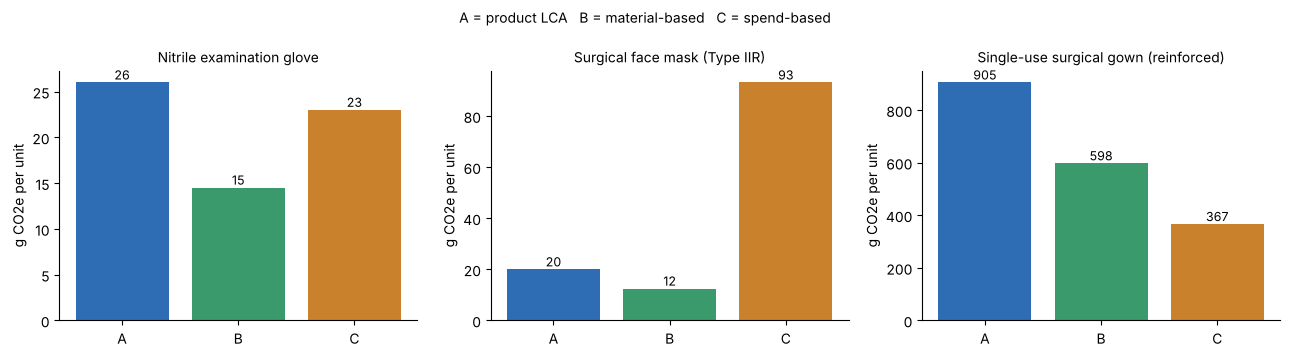

In [6]:
items = ['GLOVE_NITRILE', 'MASK_IIR', 'GOWN_SURGICAL']
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
colors = {'A': '#2E6DB4', 'B': '#3A9A6B', 'C': '#C9822B'}
for ax, p in zip(axes, items):
    res = [r for r in oc.compare(db, p) if r.available]
    ax.bar([r.method for r in res], [r.g_co2e for r in res], color=[colors[r.method] for r in res])
    for i, r in enumerate(res):
        ax.text(i, r.g_co2e, f'{r.g_co2e:.0f}', ha='center', va='bottom', fontsize=9)
    ax.set_title(db.products[p]['name'], fontsize=10)
    ax.set_ylabel('g CO2e per unit'); ax.spines[['top', 'right']].set_visible(False)
fig.suptitle('A = product LCA   B = material-based   C = spend-based', fontsize=10)
plt.tight_layout(); plt.show()

### What the comparison shows

* **B is always below A** (about 55–66% of it), as expected for a lower bound: it leaves out manufacturing energy, transport and packaging.
* **C depends on the price, not on the material.** For the glove it lands close to A (23 vs 26 g), but for the mask it is more than four times higher (93 vs 20 g), because a procedure mask is cheap to make but sold at a higher price per gram. For the gown, the only public price is for an isolation gown, a different product, so the comparison is not like for like.
* **The drapes have no product-level LCA**, so the hybrid approach falls back to method B, which is exactly what Waters et al. did.

This spread is the reason the Literature Review recommends a hierarchy of sources (Table 11) and reporting the tier of every result.

### Tier 1 example: the manufacturer's own figure

Top Glove published a life cycle result for its conventional nitrile powder-free glove (size M, 3.5 g): 0.0277 kg CO₂e per glove, from raw material extraction to disposal, verified by SATRA Technology (press release, 3 September 2024). Because the figure belongs to a named product, it is Tier 1, and the hybrid choice uses it first. It would be Tier 1 for Soroka only if this is the glove Soroka buys.

In [7]:
r = oc.hybrid(db, 'GLOVE_TOPGLOVE')
print(r.tier); print(*r.steps, sep='\n')

Tier 1 - footprint of this exact product (manufacturer, EPD or MedZero)
Emission factor of the product: 27.7 g CO2e per one glove (cradle-to-grave (raw material extraction to disposal)).
CF = quantity x EF = 1 x 0.0277 kg = 0.0277 kg CO2e.


## Verification: reproducing a published result

Waters et al. reported 93.9 kg of polypropylene drapes and 292 kg CO₂e for 159 operations. Method B with the UK polypropylene factor, without disposal, reproduces this value within 0.5%.

In [8]:
r = oc.material_based(db, 'DRAPES_GYN_CASE', quantity=159, include_disposal=False)
print(f'Method B: {r.kg_co2e:.1f} kg CO2e   (published: 292 kg CO2e)')
print(f'Implied factor in Waters et al.: {292 / 93.9:.3f} kg CO2e/kg;  UK factor used: {db.material_factor["polypropylene"]["value"]:.3f}')

Method B: 291.5 kg CO2e   (published: 292 kg CO2e)
Implied factor in Waters et al.: 3.110 kg CO2e/kg;  UK factor used: 3.105


## Anaesthetic gases

$$CF = m_{\text{agent}} \times GWP_{100}, \qquad m = V_{\text{liquid}} \times \text{specific gravity}$$

GWP100 values from IPCC AR6 (desflurane 2,590; sevoflurane 195). Bottle volumes and specific gravities from the FDA labels. All of the agent is assumed to reach the atmosphere.

In [9]:
for a in ['desflurane', 'sevoflurane']:
    r = oc.anaesthetic_gas(db, a, bottles=1)
    print(a.ljust(12), *r.steps, sep='  |  ')

desflurane    |  1 bottle(s) x 240 mL = 240 mL of liquid desflurane  |  mass = 240 mL x 1.465 g/mL = 351.6 g  |  CF = 351.6 g x GWP100 2590 = 910.64 kg CO2e
sevoflurane   |  1 bottle(s) x 250 mL = 250 mL of liquid sevoflurane  |  mass = 250 mL x 1.52 g/mL = 380.0 g  |  CF = 380.0 g x GWP100 195 = 74.10 kg CO2e


## One operation (illustrative quantities)

The quantities below are **illustrative, not measured**; the emission factors are the real ones above. Each item uses the hybrid choice. The footprint of the items that were opened but not used is calculated separately, as in Section 7.2 of the Literature Review.

In [10]:
res = oc.case_footprint(db,
    [('GLOVE_TOPGLOVE', 20, 4), ('MASK_IIR', 6, 1), ('GOWN_SURGICAL', 4, 1), ('DRAPES_GYN_CASE', 1, 0)],
    gas=('sevoflurane', 20))
print(pd.DataFrame([{'product': l.name, 'opened': l.opened, 'unused': l.unused, 'method': l.method,
                     'kg CO2e opened': round(l.kg_opened, 3), 'kg CO2e unused': round(l.kg_unused, 3)} for l in res['lines']]).to_string(index=False))
print(f"\nSupplies {res['supplies_kg']:.2f} kg  |  unused {res['unused_kg']:.2f} kg ({res['unused_share_of_supplies']:.0%})  |  gas {res['gas_kg']:.2f} kg  |  total {res['total_kg']:.2f} kg CO2e")

                                                   product  opened  unused method  kg CO2e opened  kg CO2e unused
                Nitrile examination glove, Top Glove 3.5 g      20       4      A           0.554           0.111
                             Surgical face mask (Type IIR)       6       1      A           0.120           0.020
                     Single-use surgical gown (reinforced)       4       1      A           3.620           0.905
Single-use surgical drapes for one gynecological operation       1       0      B           2.468           0.000

Supplies 6.76 kg  |  unused 1.04 kg (15%)  |  gas 3.90 kg  |  total 10.66 kg CO2e


### Data quality: share of each tier (Section 7.1)

Every result reports how much of its CO₂e rests on each tier of Table 11. Here the gloves use the manufacturer's own figure (Tier 1), the masks and gowns a published LCA of an equivalent product (Tier 2), and the drapes a material-based estimate (Tier 3).

In [11]:
print({f'Tier {t}': f'{s:.0%}' for t, s in res['tier_share'].items()})

{'Tier 1': '8%', 'Tier 2': '55%', 'Tier 3': '36%', 'Tier 4': '0%'}


### Sensitivity analysis (Table 12, level 4)

The Tier 3 and Tier 4 factors are varied one at a time by ±30%, and the waste route of the material-based items is switched between the three real routes. The ±30% is an analysis setting, not a measured uncertainty.

In [12]:
case = [('GLOVE_TOPGLOVE', 20, 4), ('MASK_IIR', 6, 1), ('GOWN_SURGICAL', 4, 1), ('DRAPES_GYN_CASE', 1, 0)]
pd.DataFrame(oc.sensitivity(db, case, gas=('sevoflurane', 20), variation=0.30)).round(2)

,parameter,low_kg,high_kg,base_kg,range_kg
0,Tier 3: material emission factors ±30%,10.11,11.21,10.66,1.10
1,Waste route: high temperature incineration / a...,10.13,10.66,10.66,0.53
2,Tier 3: waste-route emission factors ±30%,10.47,10.85,10.66,0.38
3,Tier 4: spend-based emission factors ±30%,10.66,10.66,10.66,0.00


## Limitations and next steps

* The factors come from the UK, the USA, Canada and Australia; Israeli factors and Soroka's own prices and waste routes should replace them.
* Method B has no factor yet for aluminium (0.2 g in the mask) and excludes packaging.
* Rizan et al. is a preprint; the synthetic-rubber and polypropylene factors were read from Climatiq's copies of the original data sets.
* The EPA factors use IPCC AR5 GWPs, while the gas calculation uses AR6.
* Transport is not yet added to the material-based method (Table 11 lists it 'where known').
* Next: product-specific factors (MedZero, manufacturers), a factor for each Soroka waste route, and a validation against items weighed during the hospital visit.